# NGUYỄN THÀNH TRÍ - MSSV: 6451071079
## BÀI 2: PHÂN LỚP ẢNH CHỮ SỐ VIẾT TAY MNIST VỚI NEURAL NETWORK
### (MÔ HÌNH TUẦN TỰ KERAS - TRAIN / VALIDATION / TEST)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import keras
from keras import layers, models

print("Đã tải đầy đủ các thư viện cần thiết cho Bài 2.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


I0000 00:00:1794279850.707207   57125 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Đã tải đầy đủ các thư viện cần thiết cho Bài 2.


I0000 00:00:1794279851.914846   57125 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Câu a: Đọc bộ dữ liệu train, test của MNIST từ Keras
Hướng dẫn: Sử dụng keras.datasets.mnist.load_data() để đọc bộ dữ liệu vào (train_images, train_labels) và (test_images, test_labels).

In [2]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()
print("Đã nạp thành công bộ dữ liệu MNIST từ Keras.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Đã nạp thành công bộ dữ liệu MNIST từ Keras.


### Câu b: In ra kích thước của tập train và test
Hướng dẫn: Sử dụng thuộc tính .shape của các mảng dữ liệu ảnh và nhãn.

In [3]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

print(f"Kích thước tập ảnh train: {train_images.shape}")
print(f"Kích thước tập nhãn train: {train_labels.shape}")
print(f"Kích thước tập ảnh test:  {test_images.shape}")
print(f"Kích thước tập nhãn test:  {test_labels.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập ảnh train: (60000, 28, 28)
Kích thước tập nhãn train: (60000,)
Kích thước tập ảnh test:  (10000, 28, 28)
Kích thước tập nhãn test:  (10000,)


### Câu c: Chuẩn hóa các giá trị pixel của ảnh về đoạn [0, 1]
Hướng dẫn: Chia các giá trị pixel cho 255.0 để đưa cường độ sáng về thang đo số thực [0, 1].

In [4]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

print(f"Giá trị pixel nhỏ nhất sau chuẩn hóa: {train_images.min():.1f}")
print(f"Giá trị pixel lớn nhất sau chuẩn hóa: {train_images.max():.1f}")
print(f"Kiểu dữ liệu của mảng ảnh: {train_images.dtype}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Giá trị pixel nhỏ nhất sau chuẩn hóa: 0.0
Giá trị pixel lớn nhất sau chuẩn hóa: 1.0
Kiểu dữ liệu của mảng ảnh: float32


### Câu d: Chia tập train ban đầu thành tập train và validation theo tỷ lệ 8:2
Hướng dẫn: Sử dụng train_test_split từ sklearn với test_size=0.2, random_state=42. In kích thước các tập sau khi chia.

In [5]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

train_images, validation_images, train_labels, validation_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42, stratify=train_labels
)

print(f"Kích thước tập train mới (ảnh):      {train_images.shape}")
print(f"Kích thước tập train mới (nhãn):     {train_labels.shape}")
print(f"Kích thước tập validation (ảnh):     {validation_images.shape}")
print(f"Kích thước tập validation (nhãn):    {validation_labels.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập train mới (ảnh):      (48000, 28, 28)
Kích thước tập train mới (nhãn):     (48000,)
Kích thước tập validation (ảnh):     (12000, 28, 28)
Kích thước tập validation (nhãn):    (12000,)


### Câu e: Xây dựng mạng Neural Network gồm các tầng (layers)
Cấu trúc mạng tuần tự:
- Flatten layer: Làm phẳng ảnh 2D (28x28) thành vector 1D (784 chiều).
- Dense layer: 128 nơ-ron, hàm kích hoạt ReLU, Fully connected.
- Dropout layer: Tỷ lệ 0.2 (ngẫu nhiên tắt 20% nơ-ron để chống hiện tượng overfitting).
- Dense layer (Output): 10 nơ-ron, hàm kích hoạt Softmax, Fully connected.

In [6]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
], name="MNIST_Sequential_MLP")

model.summary()

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Model: "MNIST_Sequential_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Câu f: Biên dịch mô hình Neural Network
Thiết lập cấu hình huấn luyện:
- Thuật toán tối ưu hóa (Optimizer): `adam`.
- Hàm mất mát (Loss): `sparse_categorical_crossentropy`.
- Độ đo đánh giá (Metric): `accuracy`.

In [7]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Đã biên dịch mô hình thành công với optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'].")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Đã biên dịch mô hình thành công với optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'].


### Câu g: Huấn luyện mô hình trên tập train và đánh giá với tập validation
Thiết lập tham số huấn luyện:
- Số chu kỳ học (`epochs`): 5.
- Kích thước batch (`batch_size`): 32.
- Dữ liệu kiểm định: `validation_data=(validation_images, validation_labels)`.

In [8]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

history = model.fit(
    train_images,
    train_labels,
    epochs=5,
    batch_size=32,
    validation_data=(validation_images, validation_labels),
    verbose=1
)
print("Quá trình huấn luyện mô hình đã hoàn tất.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Epoch 1/5


   1/1500 ━━━━━━━━━━━━━━━━━━━━ 12:14 490ms/step - accuracy: 0.0625 - loss: 2.3410

  27/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4884 - loss: 1.6594     

  56/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6417 - loss: 1.2344

  87/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7094 - loss: 1.0189

... (246 outputs left out)

1454/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9754 - loss: 0.0804

1484/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9754 - loss: 0.0802

1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9753 - loss: 0.0803 - val_accuracy: 0.9742 - val_loss: 0.0867


Quá trình huấn luyện mô hình đã hoàn tất.


### Câu h: Vẽ biểu đồ thể hiện Accuracy và Loss qua từng epoch cho tập train và validation
Hướng dẫn: Sử dụng dữ liệu lưu trong `history.history` để vẽ 2 đồ thị con (Subplots) so sánh Accuracy và Loss giữa tập train và validation.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


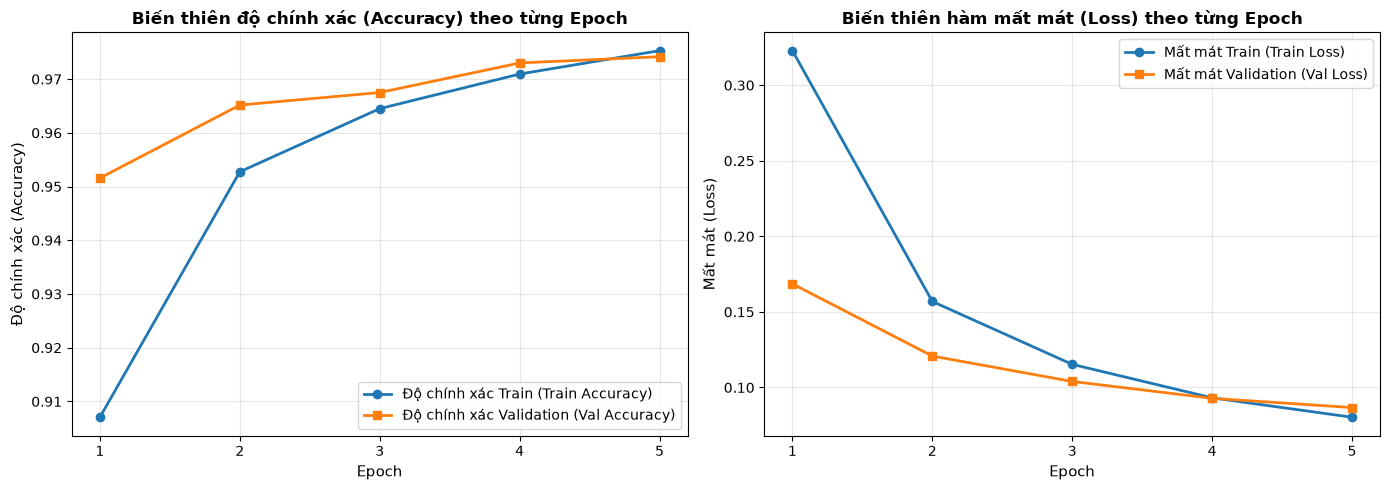

In [9]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

epochs_range = range(1, 6)

plt.figure(figsize=(14, 5))

# Biểu đồ Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], marker='o', color='#1f77b4', linewidth=2, label='Độ chính xác Train (Train Accuracy)')
plt.plot(epochs_range, history.history['val_accuracy'], marker='s', color='#ff7f0e', linewidth=2, label='Độ chính xác Validation (Val Accuracy)')
plt.title('Biến thiên độ chính xác (Accuracy) theo từng Epoch', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Độ chính xác (Accuracy)', fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.grid(True, alpha=0.3)
plt.xticks(epochs_range)

# Biểu đồ Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], marker='o', color='#1f77b4', linewidth=2, label='Mất mát Train (Train Loss)')
plt.plot(epochs_range, history.history['val_loss'], marker='s', color='#ff7f0e', linewidth=2, label='Mất mát Validation (Val Loss)')
plt.title('Biến thiên hàm mất mát (Loss) theo từng Epoch', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Mất mát (Loss)', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, alpha=0.3)
plt.xticks(epochs_range)

plt.tight_layout()
plt.show()

### Câu i: Dự đoán phân lớp cho toàn bộ tập test
Hướng dẫn: Sử dụng `model.predict` để tính phân phối xác suất dự đoán cho tập `test_images`, sau đó dùng `np.argmax(axis=1)` để lấy nhãn chữ số có xác suất cao nhất.

In [10]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

y_pred_probs = model.predict(test_images, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(f"Tổng số mẫu dự đoán trên tập test: {len(y_pred)}")
print(f"Dự đoán 10 nhãn đầu tiên:          {y_pred[:10].tolist()}")
print(f"Nhãn thực tế 10 mẫu đầu tiên:      {test_labels[:10].tolist()}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


Tổng số mẫu dự đoán trên tập test: 10000
Dự đoán 10 nhãn đầu tiên:          [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]
Nhãn thực tế 10 mẫu đầu tiên:      [7, 2, 1, 0, 4, 1, 4, 9, 5, 9]


### Câu j: Tính và in ra Accuracy của mô hình trên tập test
Hướng dẫn: Sử dụng hàm `accuracy_score(test_labels, y_pred)` từ sklearn để đánh giá độ chính xác tổng quát.

In [11]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

test_acc = accuracy_score(test_labels, y_pred)
print(f"Độ chính xác (Accuracy) của Neural Network trên tập test: {test_acc:.4f} ({test_acc * 100:.2f}%)")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Độ chính xác (Accuracy) của Neural Network trên tập test: 0.9736 (97.36%)
